# AdaBoost for classification

[Master Tree Ensemble Models course](https://www.trainindata.com/p/master-tree-ensemble-models)

In this notebook, we train an AdaBoost to predict which clients subscribe to a term deposit. We look at the predictions that the model returns, then we see how the performance changes with the number of trees, and finally we explore the trade off between the learning rate and the size of the ensemble.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split

### Load data

We use the bank marketing data that we prepared in the notebook of the folder prepare-data.

In [2]:
df = pd.read_csv("../prepare-data/bank_marketing.csv")
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,NaN,0,unknown,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,NaN,0,unknown,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,NaN,0,unknown,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,NaN,0,unknown,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,NaN,0,unknown,0


In [3]:
# the trees from Scikit-learn take numbers, so we replace the categories by integers
categorical_vars = df.select_dtypes("str").columns
df[categorical_vars] = df[categorical_vars].apply(lambda var: var.astype("category").cat.codes)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,4,1,2,0,2143,1,0,2,5,8,261,1,NaN,0,3,0
1,44,9,2,1,0,29,1,0,2,5,8,151,1,NaN,0,3,0
2,33,2,1,1,0,2,1,1,2,5,8,76,1,NaN,0,3,0
3,47,1,1,3,0,1506,1,0,2,5,8,92,1,NaN,0,3,0
4,33,11,2,3,0,1,0,0,2,5,8,198,1,NaN,0,3,0


In [4]:
# AdaBoost does not take missing values. From a theoretical perspective
# it could, but sklearn's implementation at the moment does not allow
# it. Maybe in future versions.
# For now, we replace NaN by a value outside the distribution.

df["pdays"] = df["pdays"].fillna(-1)

df.isnull().sum().sum()

np.int64(0)

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns="y"),
    df["y"],
    test_size=0.3,
    stratify=df["y"],
    random_state=0,
)

X_train.shape, X_test.shape

((31647, 16), (13564, 16))

### Train the model with the default parameters

We show the hyperparameters with their default values, so that we can see the effect of changing them later on. When we leave the estimator empty, AdaBoost trains decision trees with a depth of one, that is, trees that make a single question, which we call stumps.

In [6]:
ada = AdaBoostClassifier(
    estimator=None,   # defaults to stumps
    n_estimators=50,
    learning_rate=1.0,
    random_state=0,
)

ada.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](50,)","[0.12,0.28,0.42,...,0.49,0.49,0.49]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](50,)","[2.02,0.95,0.33,...,0.04,0.06,0.05]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=209652396), DecisionTreeC...ate=398764591), DecisionTreeC...ate=924231285), DecisionTreeC...te=1478610112), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](16,)","[0.08,0. ,0. ,...,0.11,0.02,0.06]"


In [7]:
ada.estimator_

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

### The predictions

The model returns the class with `predict`, and the probability of each class with `predict_proba`.

In [8]:
ada.predict(X_test)[:10]

array([0, 0, 0, 1, 0, 0, 1, 0, 0, 0])

In [9]:
ada.predict_proba(X_test)[:5].round(4)

array([[0.633 , 0.367 ],
       [0.6067, 0.3933],
       [0.7558, 0.2442],
       [0.4338, 0.5662],
       [0.6033, 0.3967]])

Each tree of the ensemble votes for a class, and the vote of each tree weighs as much as the accuracy that the tree showed during training, which is the value that AdaBoost stores in `estimator_weights_`. To obtain the probabilities, AdaBoost adds up the weights of the trees that voted for each class and then divides by the total weight, so that the two numbers of each row add up to one.

This means that the probability is really a measure of the agreement between the trees, and not an estimate of how often a client like this one subscribes. The probabilities are therefore not calibrated, and in this dataset they never leave the interval between 0.19 and 0.69, even for the clients that the model is most sure about.

In [10]:
# the alpha for each decision tree
ada.estimator_weights_[:5].round(3)

array([2.021, 0.951, 0.332, 0.722, 0.534])

In [11]:
# the estimator error
ada.estimator_errors_[:5]

array([0.11697791, 0.27869588, 0.41771487, 0.32697569, 0.36958051])

In [13]:
# the alpha calculation as we discussed in the class
import numpy as np
np.log((1-0.11697791)/0.11697791)

np.float64(2.0213651037252394)

### Evaluate the model

In [14]:
def evaluate(model, X_train, y_train, X_test, y_test):
    for name, X, y in [("train", X_train, y_train), ("test", X_test, y_test)]:
        balanced_accuracy = balanced_accuracy_score(y, model.predict(X))
        roc_auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
        print(f"{name} balanced accuracy: {balanced_accuracy:.4f}, roc-auc: {roc_auc:.4f}")


evaluate(ada, X_train, y_train, X_test, y_test)

train balanced accuracy: 0.6335, roc-auc: 0.8947
test balanced accuracy: 0.6398, roc-auc: 0.8888


### Performance against the number of trees

AdaBoost adds the trees one after the other, so we can evaluate the ensemble after each new tree with `staged_predict_proba`, and we obtain the whole curve by training the model only once.

In [15]:
ada = AdaBoostClassifier(n_estimators=300, random_state=0)
ada.fit(X_train, y_train)

train_curve = [roc_auc_score(y_train, p[:, 1]) for p in ada.staged_predict_proba(X_train)]
test_curve = [roc_auc_score(y_test, p[:, 1]) for p in ada.staged_predict_proba(X_test)]

len(train_curve)

300

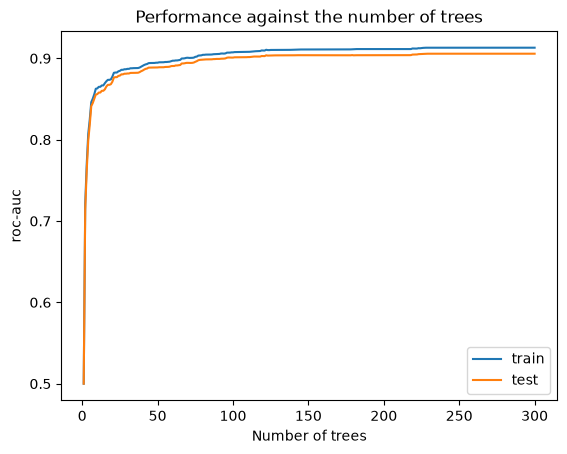

In [16]:
trees = range(1, len(train_curve) + 1)

plt.plot(trees, train_curve, label="train")
plt.plot(trees, test_curve, label="test")
plt.xlabel("Number of trees")
plt.ylabel("roc-auc")
plt.title("Performance against the number of trees")
plt.legend()
plt.show()

The performance improves very quickly with the first trees and then it continues to improve slowly, and the two curves stay close to each other, which tells us that the ensemble of stumps is not overfitting.

### The learning rate and the number of trees

The learning rate multiplies the contribution of each tree, so with a small learning rate every tree moves the ensemble a little, and we need more trees to arrive at the same place. We train the model with different learning rates and we follow the performance in the test set tree after tree.

In [17]:
learning_rates = [0.05, 0.1, 0.5, 1.0]

curves = {}
for learning_rate in learning_rates:
    model = AdaBoostClassifier(n_estimators=500, learning_rate=learning_rate, random_state=0)
    model.fit(X_train, y_train)
    curves[learning_rate] = [roc_auc_score(y_test, p[:, 1]) for p in model.staged_predict_proba(X_test)]

curves = pd.DataFrame(curves, index=range(1, 501))
curves.tail(1).round(4)

,0.05,0.10,0.50,1.00
500,0.8824,0.8882,0.906,0.9078


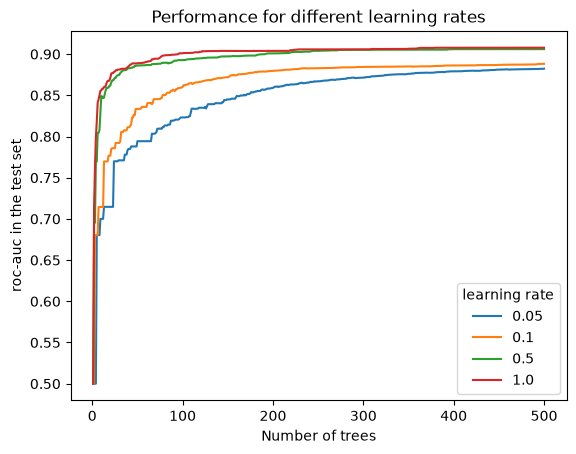

In [18]:
curves.plot()
plt.xlabel("Number of trees")
plt.ylabel("roc-auc in the test set")
plt.title("Performance for different learning rates")
plt.legend(title="learning rate")
plt.show()

The curves of the small learning rates climb slowly and they are still climbing when we run out of trees, while the curves of the large learning rates arrive at a good performance with few trees. There is a trade-off between these two hyperparameters, so it is important to tune them together.